# Clustering Task: Motor Imagery

In this notebook, we perform clustering tasks on the open dataset BCI Competition IV 2a. Here we however take a single subject data, and observe the clustering between two tasks - Right Hand and Left Hand

In this notebook, we only stick with single subject, the reason being, different subjects have different electrophysiology and the clustering algorithm would cluster subjects instead of tasks. This is a fundamental problem of electrophysiology and hence we choose only one subject. The goal of the clustering task is to establish whether a strong neural characterizaation can exist between left and right hand tasks. Understanding this might help us later when we develop foundational and semi-supervised models related to this. 

In [1]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

mne.set_log_level('ERROR')

In [2]:
%matplotlib widget

In [23]:
raw_train_1 = mne.io.read_raw_gdf("../datasets/A01T.gdf")
raw_eval_1 = mne.io.read_raw_gdf("../datasets/A01E.gdf")

In [24]:
from sklearn.covariance import OAS
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

## Epoching (left vs right)

We have a time series data, and just like our previous iterations, we epoch our data based on the internal markers corresponding to the cue of an event

In [25]:
def prepare(raw):
    raw.load_data()
    raw.pick([c for c in raw.ch_names if not c.startswith('EOG')])
    raw.filter(8, 30, fir_design='firwin')                      
    ann = raw.annotations                                       
    desc = np.where(ann.description == '1023', 'BAD_artifact', ann.description)
    raw.set_annotations(mne.Annotations(ann.onset, ann.duration, desc, orig_time=ann.orig_time))
    events, _ = mne.events_from_annotations(raw, event_id={'769': 1, '770': 2})   
    return mne.Epochs(raw, events, tmin=0.5, tmax=2.5, baseline=None,
                      preload=True, reject_by_annotation=True)

epochs = prepare(raw_train_1)
X = epochs.get_data()              
y_true = epochs.events[:, 2]       
print(X.shape, np.bincount(y_true)[1:])

(138, 22, 501) [69 69]


## Unsupervised feature extraction (covariance -> tangent space -> PCA)

Unlike the feature extraction step done earlier (Common Spatial Patterns (CSP)) which was supervised and hence required class labels. Since this is a clustering task, we implement a feature extraction technique which doesnt use class variables.

1. We first find the covariance matrix (22 x 22) for every trial using Oracle Approximating Shrinkage (OAS)
2. Find the reference covariance by taking the matrix log of every covariance, and averagign them, and map it back to matrix exponential. 
3. Re-express every trial relative to center (whitened matrix)
4. Take the matrix logarithm of the whitened matrix

Now each of the cell becomes a feature, since the matrix is symmetric, we only need one half of it, which yields us 22*23/2 = 253 features.

Later, PCA is done to reduce the dimensions. Lower number of compoenents gave us better clustering, likely due to the information about the noise not being included in the top ranked dimensions. This perhaps gave less overlapping

In [26]:
def symfun(C, f):
    w, v = np.linalg.eigh(C)
    return (v * f(w)) @ v.T

covs = np.array([OAS().fit(x.T).covariance_ for x in X])                     
ref = symfun(np.mean([symfun(c, np.log) for c in covs], axis=0), np.exp)     
W = symfun(ref, lambda w: w ** -0.5)
iu = np.triu_indices(covs.shape[1])
coef = np.where(iu[0] == iu[1], 1.0, np.sqrt(2))
F = np.array([symfun(W @ c @ W, np.log)[iu] * coef for c in covs])           

Fs = StandardScaler().fit_transform(F)
pca = PCA(n_components=10, random_state=0)
Z = pca.fit_transform(Fs)
print(F.shape, '->', Z.shape, '| explained var:', pca.explained_variance_ratio_.sum().round(3))

(138, 253) -> (138, 10) | explained var: 0.294


## K-Means: elbow curve

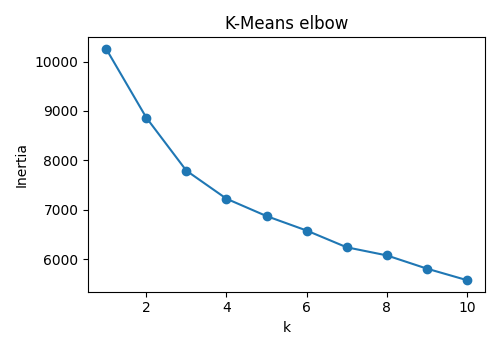

In [27]:
ks = range(1, 11)
inertia = [KMeans(k, n_init=10, random_state=0).fit(Z).inertia_ for k in ks]

plt.figure(figsize=(5, 3.5))
plt.plot(ks, inertia, 'o-')
plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('K-Means elbow')
plt.tight_layout()
plt.show()

K = 2 

>**Insight** The rate decreases after 2-3 indicating that the features can cluster atmost those numbers, which indicated a moderately strong neural correlate about the distinction between left hand and right hand motor imagery

In [28]:
labels = {}
labels['KMeans'] = KMeans(K, n_init=20, random_state=0).fit_predict(Z)

## Hierarchical: dendrograms and linkage comparison

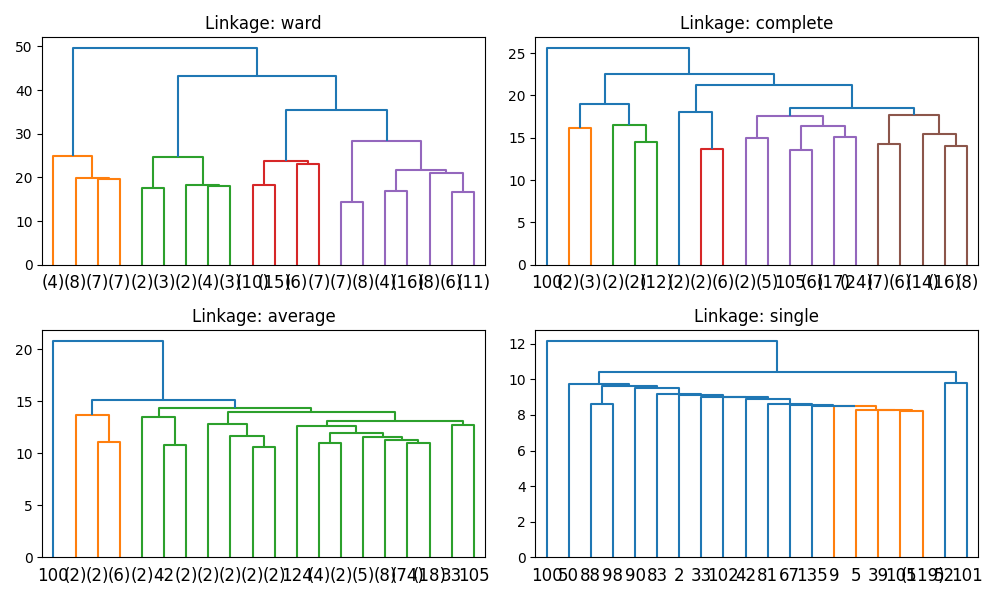

In [29]:
methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, m in zip(axes.ravel(), methods):
    dendrogram(linkage(Z, m), truncate_mode='lastp', p=20, ax=ax)
    ax.set_title(f'Linkage: {m}')
plt.tight_layout()
plt.show()

for m in methods:
    labels[f'Agglo-{m}'] = AgglomerativeClustering(K, linkage=m).fit_predict(Z)

>**Insight:** Minimizing total within cluster variance (in ward's) generated 4 clusters. Perhaps this method of clustering is unable to find clear electrophysiological distinction between tasks

## Evaluation metrics

In [30]:
rows = []
for name, l in labels.items():
    rows.append({'Algorithm': name,
                 'Silhouette': silhouette_score(Z, l),
                 'Davies-Bouldin': davies_bouldin_score(Z, l),
                 'Calinski-Harabasz': calinski_harabasz_score(Z, l),
                 'ARI (vs true)': adjusted_rand_score(y_true, l)})
pd.DataFrame(rows).set_index('Algorithm').round(3)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (vs true)
Algorithm,,,,
KMeans,0.165,2.117,21.356,0.224
Agglo-ward,0.163,2.020,18.535,0.117
Agglo-complete,0.428,0.424,5.033,0.000
Agglo-average,0.428,0.424,5.033,0.000
Agglo-single,0.428,0.424,5.033,0.000


For Agglo-complete, avg, single
>**Insight**: These methods suffered from severe cluster imbalance, assigning $ 99\%$ of samples to one giant cluster and isolating single outliers. While internal metrics (Silhouette, DB) look artificially optimal due to the high density of the single dominant cluster, the ARI of $0.000$ confirms zero alignment with ground-truth motor imagery tasks.

For KMeans, Agglo-ward
>**Insight**: Variance-minimizing algorithms successfully forced balanced cluster sizes, capturing non-random neural patterns aligned with left vs. right hand motor imagery (ARI $> 0$). The modest ARI range ($0.18–0.22$) reflects the inherently noisy and non-linearly separable nature of single-subject raw EEG feature space.

## PCA 2D scatter

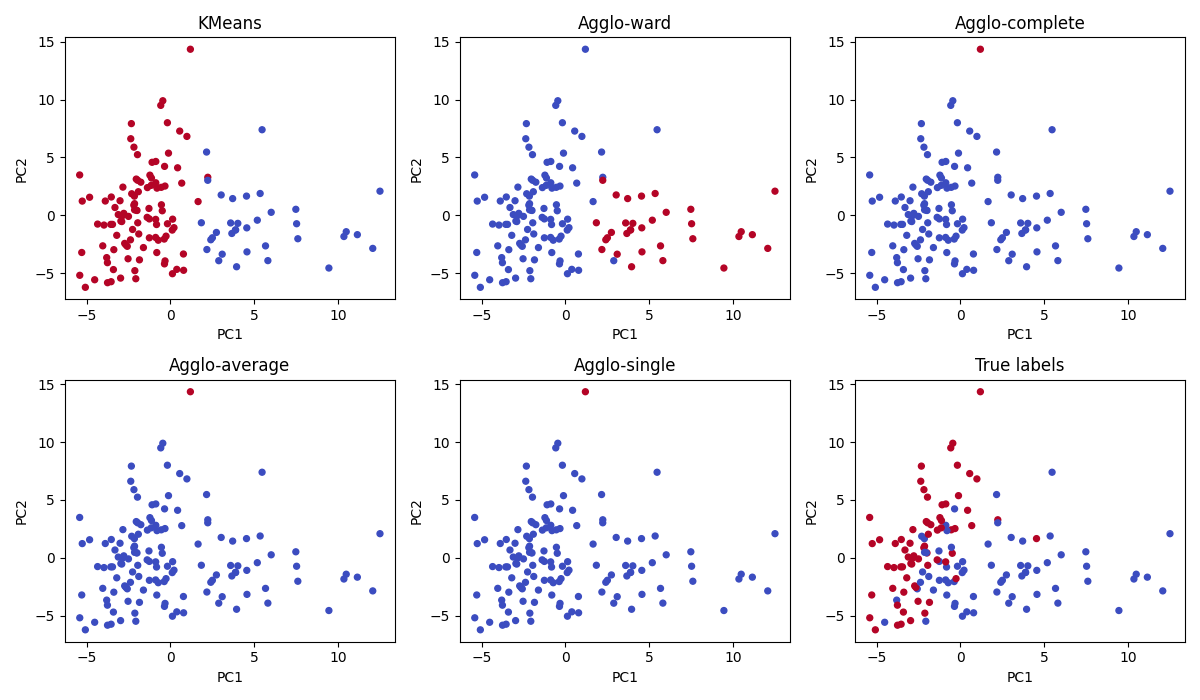

In [106]:
Z2 = PCA(2, random_state=0).fit_transform(Fs)
panels = {**labels, 'True labels': y_true}

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (name, l) in zip(axes.ravel(), panels.items()):
    ax.scatter(Z2[:, 0], Z2[:, 1], c=l, cmap='coolwarm', s=18)
    ax.set_title(name); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

## t-SNE

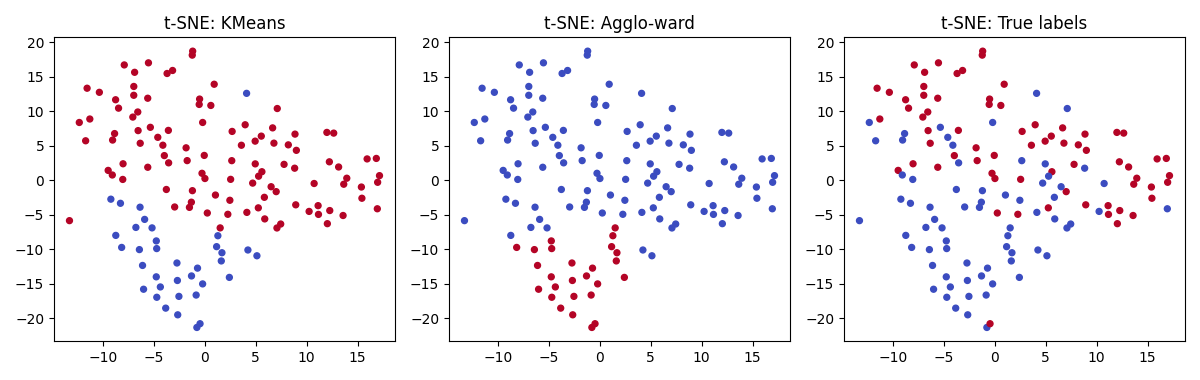

In [31]:
T = TSNE(2, perplexity=15, random_state=0).fit_transform(Z)
panels = {'KMeans': labels['KMeans'], 'Agglo-ward': labels['Agglo-ward'], 'True labels': y_true}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, l) in zip(axes, panels.items()):
    ax.scatter(T[:, 0], T[:, 1], c=l, cmap='coolwarm', s=18)
    ax.set_title(f't-SNE: {name}')
plt.tight_layout(); plt.show()